# Section 6 · Use the estimator primitive

Exam weight: 12% of C1000-179 · about 8 of the 68 questions

## Study path

**Core first pass:** Write Estimator PUBs, map observables, interpret evs/stds, relate precision to shots, configure resilience levels and ZNE, and explain Pauli expectation values and error-management techniques.

- Core coding practice: **6.1–6.5**.
- Optional second pass: **6.6–6.7 and the manual ZNE section (gate-folding code and Richardson coefficients); the warning demonstration and marked validation/overhead questions.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Estimator workflow and options](#s6-core-2) · [Estimator theory](#s6-core-57) · [Review](#s6-core-88)

Official objectives
- 6.1 Set estimator primitive options such as resilience levels
- 6.2 Understand the theoretical background behind the estimator primitive

Topics
- write valid Estimator PUBs `(circuit, observables[, parameter_values[, precision]])`, map observables to ISA circuits with `apply_layout`, and read `evs`, `stds` and the metadata;
- convert between precision and shots (shots ≈ 1/precision²) and say which setting wins when several are given;
- configure `EstimatorOptions`: what `resilience_level` 0/1/2 switches on, the `resilience.*` options for TREX, ZNE, PEA and PEC, `twirling.*` and `dynamical_decoupling.*`, and which combinations raise errors;
- explain how an expectation value is built from Pauli measurements, why commuting terms are grouped, and where the $1/\sqrt{N}$ error comes from;
- tell error suppression, mitigation and correction apart and compare the cost and bias of DD, twirling, TREX, ZNE, PEA and PEC;
- switch runtime mitigation off and implement zero-noise extrapolation yourself.

Built from the Qiskit Advocate KR study notebooks `1_Set_Estimator_Options_ko.ipynb`, `2_Understand_Estimator_Theory_KR.ipynb` and `Review/Practice_10_Qiskit_Primitives.ipynb` (Q1–Q3), and the QAMP 2025 tutorial (Section 6). Links are in the Sources cell at the end.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Pauli, Operator, Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import EstimatorV2, SamplerV2, EstimatorOptions
from qiskit_ibm_runtime.fake_provider import FakeManilaV2, FakeBrisbane   # device models only

# Local testing mode reads the deprecated `max_circuits` attribute of fake backends;
# hide that library-internal DeprecationWarning.
warnings.filterwarnings("ignore", message="max_circuits is deprecated", category=DeprecationWarning)

print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")

qiskit 2.0.3 | qiskit-aer 0.17.1 | qiskit-ibm-runtime 0.40.1


<a id="s6-core-2"></a>

## 6.1 Set estimator options such as resilience levels

Before the options make sense you need the Estimator's contract: what goes in (PUBs with circuits,
observables, parameter values and a precision), what comes out (`evs`, `stds`, metadata), and how
precision turns into shots. The second half of this part is the option tree of the IBM Runtime
`EstimatorV2`, with `resilience_level` at the top.

### 6.1.1 What the Estimator computes

The Estimator returns expectation values

$$\langle O\rangle_{\theta}=\langle\psi(\theta)|\,O\,|\psi(\theta)\rangle,\qquad
O=\sum_k a_k P_k,\quad P_k\in\{I,X,Y,Z\}^{\otimes n},$$

for a state prepared by a (possibly parameterized) circuit. On hardware each Pauli term is measured
after a basis change, and the averages are combined. Section 6.2 shows how.

| | Sampler | Estimator |
|---|---|---|
| returns | bit strings (one `BitArray` per classical register) | expectation values `evs` and standard errors `stds` |
| circuit | must contain measurements | must not contain measurements (the Estimator adds basis rotations and measurements) |
| PUB | `(circuit[, parameter_values[, shots]])` | `(circuit, observables[, parameter_values[, precision]])` |
| accuracy knob | shots | precision (target standard error) |
| Runtime noise options | `dynamical_decoupling`, `twirling` | `resilience_level`, `resilience.*` (TREX, ZNE, PEA, PEC), `dynamical_decoupling`, `twirling` |

Every Estimator call in this notebook is the Runtime `EstimatorV2` (the exam's API), run locally on
Qiskit Aer: `EstimatorV2(mode=AerSimulator())` for ideal runs with shot noise only, and
`EstimatorV2(mode=AerSimulator.from_backend(FakeXxx()))` when you need a device model (coupling map,
basis gates, noise). Without IBM credentials this is local testing mode: same PUBs, same options object,
same result format as on hardware. (Qiskit also ships reference Estimator implementations for exact
statevector or generic-backend runs, but the exam is about the Runtime one.)

`qiskit_ibm_runtime.Estimator` is an alias of `EstimatorV2`. The V1 classes (`qiskit.primitives.Estimator`,
`BackendEstimator`) were removed in Qiskit 2.0.

In [2]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)                       # no measurements: the Estimator measures by itself

aer_ideal = AerSimulator()          # ideal simulator: shot noise only
estimator = EstimatorV2(mode=aer_ideal)
estimator.options.simulator.seed_simulator = 42

job = estimator.run([(bell, ["ZZ", "XX", "YY", "ZI"])])   # one PUB, four observables
pub_result = job.result()[0]

print("evs     :", pub_result.data.evs)
print("stds    :", pub_result.data.stds)
print("metadata:", pub_result.metadata)
print("exact   :", [float(np.round(Statevector(bell).expectation_value(SparsePauliOp(p)).real, 6))
                    for p in ["ZZ", "XX", "YY", "ZI"]])

evs     : [ 1.          1.         -1.         -0.01074219]
stds    : [0.        0.        0.        0.0156241]
metadata: {'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}}
exact   : [1.0, 1.0, -1.0, 0.0]


For the Bell state $(|00\rangle+|11\rangle)/\sqrt2$ the correlators are $\langle ZZ\rangle=\langle XX\rangle=1$,
$\langle YY\rangle=-1$ and the single-qubit $\langle ZI\rangle=0$. The three correlators come out exact
even though the Estimator samples 4096 shots (the default precision 0.015625): the Bell state is an
eigenstate of $ZZ$, $XX$ and $YY$, so every shot gives the same $\pm1$ and their `stds` are 0.
$\langle ZI\rangle$ fluctuates around 0 with a standard error close to $1/\sqrt{4096}$. `AerSimulator()`
supports every standard gate, so a textbook circuit is already ISA for it; device models need transpiling
(6.1.3). `Statevector` from `qiskit.quantum_info` gives the exact reference values.

What if the circuit still ends with measurements (for example copied from a Sampler example)?

In [3]:
bell_measured = bell.copy()
bell_measured.measure_all()

# The Estimator does NOT complain ...
print("circuit with measurements:      <XX> =",
      estimator.run([(bell_measured, "XX")]).result()[0].data.evs, " <- ideal value is 1")

# ... the fix: drop the terminal measurements before building the PUB
bell_clean = bell_measured.remove_final_measurements(inplace=False)
print("after remove_final_measurements: <XX> =", estimator.run([(bell_clean, "XX")]).result()[0].data.evs)

circuit with measurements:      <XX> = -0.021484375  <- ideal value is 1


after remove_final_measurements: <XX> = 1.0


Estimator circuits must not contain measurements. The local Runtime Estimator does not raise an error:
it appends its own basis rotations after your measurements, so the state has already collapsed in the Z
basis and $\langle XX\rangle$ comes back as about 0. Use `qc.remove_final_measurements(inplace=False)`
(or build the circuit without them).

### 6.1.2 The Estimator PUB

A PUB (primitive unified bloc) is a tuple, and the order of its elements is fixed:

| Position | Element | Notes |
|---|---|---|
| 1 | `circuit` | one `QuantumCircuit`, no measurements, may contain `Parameter`s |
| 2 | `observables` | anything observables-array-like: `str`, `Pauli`, `SparsePauliOp`, `PauliList`, or (nested) lists/arrays of them |
| 3 | `parameter_values` (optional) | array-like whose last axis runs over the circuit parameters; `None` if the circuit has none |
| 4 | `precision` (optional) | target standard error for this PUB; overrides `run(..., precision=)` and `default_precision` |

`estimator.run(pubs, precision=None)` takes a list of PUBs and returns one `PubResult` per PUB.
The shape of `evs` is the broadcast of the observables shape and the parameter-values shape (rules as in
NumPy; Section 4 covers them in detail). A common pattern is "every observable at every parameter value":
give the observables shape `(n_obs, 1)` and the parameter values shape `(n_values, n_params)`.

In [4]:
theta = Parameter("θ")
ry_qc = QuantumCircuit(1)
ry_qc.ry(theta, 0)

angles = np.linspace(0, np.pi, 5)          # shape (5,) -> 5 bindings of the single parameter
obs_column = [["Z"], ["X"]]                # shape (2, 1)

res = estimator.run([(ry_qc, obs_column, angles)], precision=0.01).result()[0]
print("evs shape:", res.data.evs.shape)     # (2, 1) broadcast with (5,) -> (2, 5)
print(np.round(res.data.evs, 3))
print("expected <Z> = cos θ:", np.round(np.cos(angles), 3))
print("expected <X> = sin θ:", np.round(np.sin(angles), 3))

# precision as the 4th element: with no parameters, put None in the 3rd slot
print("with precision 0.05:", estimator.run([(bell, "ZZ", None, 0.05)]).result()[0].metadata)

evs shape: (2, 5)
[[ 1.     0.697  0.019 -0.707 -1.   ]
 [-0.016  0.707  1.     0.7   -0.002]]
expected <Z> = cos θ: [ 1.     0.707  0.    -0.707 -1.   ]
expected <X> = sin θ: [0.    0.707 1.    0.707 0.   ]
with precision 0.05: {'target_precision': 0.05, 'shots': 400, 'circuit_metadata': {}}


In [5]:
# Swapping observables and parameter values is the classic mistake
try:
    estimator.run([(ry_qc, angles, "Z")]).result()
except Exception as err:
    print(type(err).__name__, "-", err)

# Broadcasting must work, otherwise the PUB is rejected
try:
    estimator.run([(ry_qc, ["Z", "X"], angles)]).result()      # (2,) vs (5,)
except Exception as err:
    print(type(err).__name__, "-", err)

TypeError - Invalid observable type: <class 'float'>
ValueError - The observables shape (2,) and the parameter values shape (5,) are not broadcastable.


Estimator PUB = `(circuit, observables, parameter_values, precision)`. The Sampler PUB has no
observables slot and ends with `shots`. Putting the parameter values second gives
`TypeError: Invalid observable type`.

Put observables that belong to the same circuit and parameter values into one PUB. Within a PUB the
Estimator can measure qubit-wise commuting terms together; commuting observables placed in different
PUBs are measured separately (see 6.2.2).

### Practice 6.1 — A parameterized Estimator PUB

`ex1_qc` prepares $\cos(\theta/2)|00\rangle+\sin(\theta/2)|11\rangle$. Build one PUB `ex1_pub` that
evaluates the three observables `ZZ`, `XX`, `ZI` (in this order) at each of the four angles in
`ex1_angles`, such that `evs` has shape `(3, 4)` (row = observable, column = angle). Run it with
`EstimatorV2(mode=AerSimulator())` (seed 1 is set in the starter) and store the `evs` array in `ex1_evs`.

In [ ]:
ex1_theta = Parameter("θ")
ex1_qc = QuantumCircuit(2)
ex1_qc.ry(ex1_theta, 0)
ex1_qc.cx(0, 1)
ex1_angles = np.array([0.0, np.pi / 4, np.pi / 2, np.pi])
ex1_est = EstimatorV2(mode=AerSimulator())
ex1_est.options.simulator.seed_simulator = 1

ex1_pub = None   # TODO: (circuit, observables with shape (3, 1), parameter values)
ex1_evs = None   # TODO: run ex1_pub with ex1_est and keep result[0].data.evs

In [ ]:
# Run this cell to check your answer
assert ex1_pub is not None and ex1_evs is not None, "fill in the TODOs"
assert ex1_pub[0] is ex1_qc, "the circuit must be the first element of the PUB"
assert np.shape(ex1_evs) == (3, 4), f"evs shape is {np.shape(ex1_evs)}, expected (3, 4)"
expected = np.array([np.ones(4), np.sin(ex1_angles), np.cos(ex1_angles)])
assert np.allclose(ex1_evs, expected, atol=0.07), "values do not match <ZZ>=1, <XX>=sin θ, <ZI>=cos θ (up to shot noise)"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_theta = Parameter("θ")
ex1_qc = QuantumCircuit(2)
ex1_qc.ry(ex1_theta, 0)
ex1_qc.cx(0, 1)
ex1_angles = np.array([0.0, np.pi / 4, np.pi / 2, np.pi])
ex1_est = EstimatorV2(mode=AerSimulator())
ex1_est.options.simulator.seed_simulator = 1

ex1_pub = (ex1_qc, [["ZZ"], ["XX"], ["ZI"]], ex1_angles)
ex1_evs = ex1_est.run([ex1_pub]).result()[0].data.evs
```

The nested list `[["ZZ"], ["XX"], ["ZI"]]` has shape `(3, 1)`; the four angles form bindings of shape
`(4,)` (the parameter axis is the implicit last axis). Broadcasting `(3, 1)` with `(4,)` gives `(3, 4)`.
A flat list `["ZZ", "XX", "ZI"]` has shape `(3,)` and would not broadcast with `(4,)`.
For this state $\langle ZZ\rangle = 1$, $\langle XX\rangle=\sin\theta$ and $\langle ZI\rangle=\cos\theta$
(`ZI` acts on qubit 1), up to shot noise of about 0.016 at the default precision.

</details>

Q6.1. Circuit `qc` has exactly one `Parameter`. Which call is a valid `EstimatorV2` request that evaluates
observable `obs` at three parameter values with a target precision of 0.01?

A. `estimator.run([(qc, [0.1, 0.2, 0.3], obs, 0.01)])`

B. `estimator.run([(qc, obs, 0.01, [0.1, 0.2, 0.3])])`

C. `estimator.run([(qc, obs, [0.1, 0.2, 0.3], 0.01)])`

D. `estimator.run([(obs, qc, [0.1, 0.2, 0.3], 0.01)])`

<details>
<summary>Show answer</summary>

Answer: C

The PUB order is circuit, observables, parameter values, precision. For a one-parameter circuit a flat
list of three numbers is three bindings, so `evs` has shape `(3,)`.
A raises `TypeError: Invalid observable type: <class 'float'>` (the values sit in the observables slot).
B raises `TypeError: precision must be a real number, not <class 'list'>`. D puts the circuit in the
observables slot and also raises a `TypeError`.

</details>

### 6.1.3 Observables and ISA circuits

Ways to write the same observable $H = Z_1Z_0 + 0.5\,X_1$ on two qubits:

| Form | Example |
|---|---|
| Pauli label (string) | `"ZZ"` (single term, coefficient 1) |
| `Pauli` | `Pauli("XI")` |
| `SparsePauliOp` from labels | `SparsePauliOp(["ZZ", "XI"], coeffs=[1.0, 0.5])` |
| `SparsePauliOp.from_list` | `SparsePauliOp.from_list([("ZZ", 1.0), ("XI", 0.5)])` |
| `SparsePauliOp.from_sparse_list` | `SparsePauliOp.from_sparse_list([("ZZ", [0, 1], 1.0), ("X", [1], 0.5)], num_qubits=2)` |
| from a matrix | `SparsePauliOp.from_operator(matrix)` |

Little-endian labels: the right-most character acts on qubit 0. `"XI"` is $X$ on qubit 1, and
`Pauli("XZ")[0]` is `Z`. In `from_sparse_list` the characters are matched to the listed indices in order,
so `("X", [1], 0.5)` is also $X$ on qubit 1.

In [6]:
h_a = SparsePauliOp.from_list([("ZZ", 1.0), ("XI", 0.5)])
h_b = SparsePauliOp.from_sparse_list([("ZZ", [0, 1], 1.0), ("X", [1], 0.5)], num_qubits=2)
print("same operator:", h_a == h_b)
print("Pauli('XZ')[0] =", Pauli("XZ")[0], "| Pauli('XZ')[1] =", Pauli("XZ")[1])

flip_q0 = QuantumCircuit(2)
flip_q0.x(0)                                   # |01> in Qiskit's |q1 q0> notation
print("<IZ>, <ZI> on X(q0)|00>:", estimator.run([(flip_q0, ["IZ", "ZI"])]).result()[0].data.evs)

same operator: True
Pauli('XZ')[0] = Z | Pauli('XZ')[1] = X
<IZ>, <ZI> on X(q0)|00>: [-1.  1.]


ISA circuits need ISA observables. Real backends (and the Runtime Estimator) accept only circuits
that use the backend's native gates and connectivity (instruction set architecture, ISA). Transpiling
maps your virtual qubits to physical qubits of a 127- or 156-qubit device, so the observable must be
re-indexed the same way: `isa_obs = obs.apply_layout(isa_circuit.layout)`.

In [7]:
brisbane = FakeBrisbane()                          # device model (127 qubits)
brisbane_sim = AerSimulator.from_backend(brisbane)   # Aer with its coupling map, basis gates, noise
ghz3 = QuantumCircuit(3)
ghz3.h(0)
ghz3.cx(0, 1)
ghz3.cx(1, 2)
ghz_obs = SparsePauliOp(["ZZI", "IZZ", "XXX"])

pm_brisbane = generate_preset_pass_manager(optimization_level=1, backend=brisbane_sim,
                                           initial_layout=[10, 11, 12], seed_transpiler=11)
isa_ghz = pm_brisbane.run(ghz3)
isa_ghz_obs = ghz_obs.apply_layout(isa_ghz.layout)

print("qubits: circuit", isa_ghz.num_qubits, "| original observable", ghz_obs.num_qubits,
      "| ISA observable", isa_ghz_obs.num_qubits)
print("virtual -> physical:", isa_ghz.layout.final_index_layout())
for label, qubits, coeff in isa_ghz_obs.to_sparse_list():
    print(f"  {label:>3} on physical qubits {qubits}  (coeff {coeff.real:+.1f})")

qubits: circuit 127 | original observable 3 | ISA observable 127
virtual -> physical: [10, 11, 12]
   ZZ on physical qubits [11, 12]  (coeff +1.0)
   ZZ on physical qubits [10, 11]  (coeff +1.0)
  XXX on physical qubits [10, 11, 12]  (coeff +1.0)


In [8]:
brisbane_est = EstimatorV2(mode=brisbane_sim)
brisbane_est.options.simulator.seed_simulator = 42

try:
    brisbane_est.run([(isa_ghz, ghz_obs)]).result()          # forgot apply_layout
except Exception as err:
    print(type(err).__name__, "-", err)

try:   # not transpiled at all; the fake backend itself as mode checks ISA like real hardware does
    EstimatorV2(mode=brisbane).run([(ghz3, ghz_obs)]).result()
except Exception as err:
    print(type(err).__name__, "-", str(err)[:100], "...")

try:
    EstimatorV2(mode=brisbane_sim, options={"optimization_level": 1})  # V1-era option, gone in V2
except Exception as err:
    print(type(err).__name__, "-", [ln.strip() for ln in str(err).splitlines()][1:3])

res = brisbane_est.run([(isa_ghz, [[o] for o in isa_ghz_obs])]).result()[0]
print("noisy evs of ZZI, IZZ, XXX:", np.round(res.data.evs.ravel(), 3), "(ideal 1, 1, 1)")

ValueError - The number of qubits of the circuit (127) does not match the number of qubits of the ()-th observable (3).
IBMInputValueError - 'The instruction h on qubits (0,) is not supported by the target system. Circuits that do not match  ...
ValidationError - ['optimization_level', 'Unexpected keyword argument [type=unexpected_keyword_argument, input_value=1, input_type=int]']


noisy evs of ZZI, IZZ, XXX: [0.655 0.651 0.636] (ideal 1, 1, 1)


Forgetting `apply_layout` gives `ValueError: The number of qubits of the circuit (127) does not match
the number of qubits of the ()-th observable (3)`. Padding the observable with identities yourself
(`obs.apply_layout(None, num_qubits=127)`) removes the error but measures the wrong physical qubits.
Always use the layout of the same transpiled circuit you submit.

`SparsePauliOp.apply_layout(layout, num_qubits=None)` accepts the circuit's `TranspileLayout`, a list of
physical indices, or `None` (then pass `num_qubits` to pad). The docs pattern to remember is
`isa_observable = observable.apply_layout(isa_circuit.layout)`.

V2 primitives do not transpile for you. `EstimatorOptions` has no `optimization_level` and no
`transpilation` group any more (both belonged to the V1 primitives): passing them raises
`ValidationError` (`Unexpected keyword argument` / `Object has no attribute 'optimization_level'`). A
circuit that is not ISA is rejected: on hardware, and in local testing mode with a fake backend as the
mode (shown above), `run()` raises `IBMInputValueError: The instruction h on qubits (0,) is not supported
by the target system`; with `AerSimulator.from_backend(...)` as the mode, Aer itself fails with
`AerError: unknown instruction: h`. Transpile
yourself with `generate_preset_pass_manager(optimization_level=..., backend=backend)` and map the
observables with `apply_layout`.

### Practice 6.2 — ISA observable on a device model

Transpile the GHZ circuit `ex2_qc` for `ex2_backend = AerSimulator.from_backend(FakeManilaV2())` with `optimization_level=1`,
`initial_layout=[4, 3, 2]` and `seed_transpiler=1`, and store it in `ex2_isa`. Map `ex2_obs` onto it
(`ex2_isa_obs`) and run the PUB `(ex2_isa, ex2_isa_obs)` with `EstimatorV2(mode=ex2_backend)`
(use `options={"simulator": {"seed_simulator": 5}}`). Store the `evs` in `ex2_evs`.

In [ ]:
ex2_qc = QuantumCircuit(3)
ex2_qc.h(0)
ex2_qc.cx(0, 1)
ex2_qc.cx(1, 2)
ex2_obs = [SparsePauliOp("ZZI"), SparsePauliOp("IZZ"), SparsePauliOp("XXX")]
ex2_backend = AerSimulator.from_backend(FakeManilaV2())

ex2_isa = None       # TODO: transpile ex2_qc (optimization_level=1, initial_layout=[4, 3, 2], seed_transpiler=1)
ex2_isa_obs = None   # TODO: list of the three observables mapped with apply_layout
ex2_evs = None       # TODO: run (ex2_isa, ex2_isa_obs) with EstimatorV2(mode=ex2_backend, ...)

In [ ]:
# Run this cell to check your answer
assert ex2_isa is not None and ex2_isa_obs is not None and ex2_evs is not None, "fill in the TODOs"
assert ex2_isa.layout.final_index_layout() == [4, 3, 2], "use initial_layout=[4, 3, 2]"
assert all(o.num_qubits == 5 for o in ex2_isa_obs), "ISA observables must act on all 5 physical qubits"
got = [(lbl, sorted(q)) for o in ex2_isa_obs for lbl, q, _ in o.to_sparse_list()]
assert got == [("ZZ", [2, 3]), ("ZZ", [3, 4]), ("XXX", [2, 3, 4])], f"unexpected mapping {got}"
assert np.shape(ex2_evs) == (3,) and np.all(np.asarray(ex2_evs) > 0.5), "evs should be three noisy values near 1"
print("ISA observables:", [o.paulis[0].to_label() for o in ex2_isa_obs])
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_qc = QuantumCircuit(3)
ex2_qc.h(0)
ex2_qc.cx(0, 1)
ex2_qc.cx(1, 2)
ex2_obs = [SparsePauliOp("ZZI"), SparsePauliOp("IZZ"), SparsePauliOp("XXX")]
ex2_backend = AerSimulator.from_backend(FakeManilaV2())

ex2_pm = generate_preset_pass_manager(optimization_level=1, backend=ex2_backend,
                                      initial_layout=[4, 3, 2], seed_transpiler=1)
ex2_isa = ex2_pm.run(ex2_qc)
ex2_isa_obs = [o.apply_layout(ex2_isa.layout) for o in ex2_obs]
ex2_est = EstimatorV2(mode=ex2_backend, options={"simulator": {"seed_simulator": 5}})
ex2_evs = ex2_est.run([(ex2_isa, ex2_isa_obs)]).result()[0].data.evs
```

Virtual qubits 0, 1, 2 sit on physical qubits 4, 3, 2. `"ZZI"` ($Z$ on virtual qubits 1 and 2) therefore
becomes $Z$ on physical qubits 3 and 2, i.e. the 5-qubit label `IZZII` (qubit 4 on the left); `"IZZ"`
($Z$ on virtual qubits 0 and 1) becomes `ZZIII`, and `"XXX"` becomes `XXXII`. The
values are below 1 because the device model's noise (gate, readout and relaxation errors) is simulated
and nothing is mitigated in local mode.

</details>

Q6.2. `isa_qc` was transpiled for a 127-qubit backend. You forget to call `apply_layout` and submit
`estimator.run([(isa_qc, SparsePauliOp("ZZ"))])` with the Runtime `EstimatorV2`. What happens?

A. A `ValueError` is raised because the circuit has 127 qubits but the observable has 2.

B. The observable is padded with identities on the other qubits and the correct value is returned.

C. The job runs and returns $\langle Z_1 Z_0\rangle$ of physical qubits 0 and 1.

D. The transpiler stored the layout in the circuit, so the Estimator re-indexes the observable automatically.

<details>
<summary>Show answer</summary>

Answer: A

PUB validation compares qubit counts and fails before anything runs
(`The number of qubits of the circuit (127) does not match the number of qubits of the ()-th observable (2)`).
Nothing is padded or re-indexed automatically; C would only happen if you padded the observable
yourself, which gives a silently wrong answer.

</details>

### 6.1.4 Precision, shots and results

`precision` is the target standard error of each expectation value. For a Pauli observable the
variance of one shot is at most 1, so $N$ shots give a standard error of at most $1/\sqrt N$. That is why
the Runtime Estimator converts precision to shots as

$$N_\text{shots}\approx\frac{1}{\text{precision}^2},\qquad
\text{default } 0.015625=\tfrac{1}{\sqrt{4096}}\ \Rightarrow\ 4096\text{ shots}.$$

Halving the precision value (asking for a smaller error) needs four times the shots; doubling it
(for example 0.01 → 0.02) needs a quarter (10,000 → 2,500).

Which setting wins in the Runtime `EstimatorV2` (highest first):
1. `precision` inside the PUB;
2. `precision=` passed to `run()`;
3. if twirling is enabled (measurement twirling is on by default at levels 1 and 2): `twirling.num_randomizations × twirling.shots_per_randomization`, when both are integers rather than `"auto"`;
4. `options.default_shots`;
5. `options.default_precision` (default 0.015625).

So if both `default_shots` and `default_precision` are set, `default_shots` is used.

In [9]:
manila = FakeManilaV2()                          # device model used for the rest of this notebook
manila_sim = AerSimulator.from_backend(manila)
pm_manila = generate_preset_pass_manager(optimization_level=1, backend=manila_sim, seed_transpiler=7)

def shots_used(options=None, run_precision=None, pub_precision=None):
    est = EstimatorV2(mode=manila_sim, options={"simulator": {"seed_simulator": 1}, **(options or {})})
    pub = (isa_bell, isa_zz) if pub_precision is None else (isa_bell, isa_zz, None, pub_precision)
    md = est.run([pub], precision=run_precision).result()[0].metadata
    return md["shots"], round(md["target_precision"], 5)

isa_bell = pm_manila.run(bell)
isa_zz = SparsePauliOp("ZZ").apply_layout(isa_bell.layout)

cases = {
    "nothing set (default_precision 0.015625)": {},
    "default_precision=0.03125": {"options": {"default_precision": 0.03125}},
    "run(..., precision=0.01)": {"run_precision": 0.01},
    "PUB precision 0.02": {"pub_precision": 0.02},
    "default_shots=5000": {"options": {"default_shots": 5000}},
    "default_shots=5000 + default_precision=0.1": {"options": {"default_shots": 5000, "default_precision": 0.1}},
    "default_shots=5000 + run(precision=0.02)": {"options": {"default_shots": 5000}, "run_precision": 0.02},
}
for name, kw in cases.items():
    shots, prec = shots_used(**kw)
    print(f"{name:45s} -> shots {shots:6d}, target_precision {prec}")

nothing set (default_precision 0.015625)      -> shots   4096, target_precision 0.01562
default_precision=0.03125                     -> shots   1024, target_precision 0.03125


run(..., precision=0.01)                      -> shots  10000, target_precision 0.01
PUB precision 0.02                            -> shots   2500, target_precision 0.02


default_shots=5000                            -> shots   5000, target_precision 0.01414
default_shots=5000 + default_precision=0.1    -> shots   5000, target_precision 0.01414
default_shots=5000 + run(precision=0.02)      -> shots   2500, target_precision 0.02


Reading the result. `job.result()` is a `PrimitiveResult`; index it per PUB. Each `PubResult` has
`data` (a `DataBin`) and `metadata`:

| Field | Meaning |
|---|---|
| `result[i].data.evs` | expectation values, shape = broadcast shape of PUB `i` |
| `result[i].data.stds` | standard errors, same shape |
| `result[i].data.ensemble_standard_error` | Runtime on hardware only (per the IBM documentation): standard error assuming shot noise alone, while `stds` is derived from the spread over twirling randomizations (the 0.40 `ZneOptions` docstring uses the same convention for `stds_noise_factors` vs `ensemble_stds_noise_factors`) |
| `result[i].metadata` | e.g. `target_precision`, `shots`, `circuit_metadata`; on hardware also `num_randomizations` and resilience information |
| `result.metadata` | job-level metadata (on hardware: the resolved `dynamical_decoupling`, `twirling`, `resilience` settings) |

Per the IBM documentation, a real `ibm_*` job returns, for example,
`DataBin(evs=..., stds=..., ensemble_standard_error=...)` with
`metadata={'shots': 4096, 'target_precision': 0.015625, 'circuit_metadata': {}, 'resilience': {}, 'num_randomizations': 32}`.
With ZNE enabled you also get `evs_extrapolated`, `stds_extrapolated`, `evs_noise_factors` and
`stds_noise_factors`, so you can inspect or refit the extrapolation yourself.

In [10]:
local_res = EstimatorV2(mode=manila_sim, options={"simulator": {"seed_simulator": 3}}).run(
    [(isa_bell, [isa_zz, SparsePauliOp("XX").apply_layout(isa_bell.layout)]),
     (isa_bell, SparsePauliOp("YY").apply_layout(isa_bell.layout))]
).result()

print(type(local_res).__name__, "with", len(local_res), "PubResults")
print("PUB 0 data:", local_res[0].data)
print("PUB 0 evs :", local_res[0].data.evs, " stds:", local_res[0].data.stds)
print("PUB 1 evs :", local_res[1].data.evs, " (0-d array -> float:", float(local_res[1].data.evs), ")")
print("PUB 0 metadata:", local_res[0].metadata)

PrimitiveResult with 2 PubResults
PUB 0 data: DataBin(evs=np.ndarray(<shape=(2,), dtype=float64>), stds=np.ndarray(<shape=(2,), dtype=float64>), shape=(2,))
PUB 0 evs : [0.87548828 0.8671875 ]  stds: [0.00755061 0.00778097]
PUB 1 evs : -0.85595703125  (0-d array -> float: -0.85595703125 )
PUB 0 metadata: {'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}}


A larger precision value is a looser target and needs fewer shots: "precision × 2 → shots ÷ 4",
"precision ÷ 2 → shots × 4". Also note that `run()` takes precision only as a keyword:
`estimator.run(pubs, precision=0.01)`; `estimator.run(pubs, 0.01)` raises
`TypeError: ... takes 2 positional arguments but 3 were given`.

> **Deeper API practice — optional on the first pass.** The different exception paths for precision=0 are deeper validation details; a positive target precision is core.

The Runtime `EstimatorV2` needs precision > 0, and where you
put the 0 decides what fails: `run(..., precision=0)` raises `ValueError: The precision value must be
strictly greater than 0.` in `run()` itself; `options.default_precision = 0` raises a Pydantic
`ValidationError` at assignment; a PUB precision of 0 is not checked by the Runtime client and, in local
testing mode, is rejected at run time with a `ValueError` ("precision less than or equal to 0").

### Practice 6.3 — Get exactly 10,000 shots per PUB

Create `ex3_est`, an `EstimatorV2` on `AerSimulator.from_backend(FakeManilaV2())` configured through its
options so that a PUB without its own precision, submitted with a plain `ex3_est.run([pub])`,
uses exactly 10,000 shots. Keep `"simulator": {"seed_simulator": 3}` in the options.

In [ ]:
ex3_est = None   # TODO: EstimatorV2(mode=AerSimulator.from_backend(FakeManilaV2()), options={...})

In [ ]:
# Run this cell to check your answer
assert ex3_est is not None, "fill in the TODO"
ex3_md = ex3_est.run([(isa_bell, isa_zz)]).result()[0].metadata
assert ex3_md["shots"] == 10_000, f"got {ex3_md['shots']} shots"
print(ex3_md)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex3_est = EstimatorV2(mode=AerSimulator.from_backend(FakeManilaV2()),
                    options={"default_precision": 0.01, "simulator": {"seed_simulator": 3}})
# equivalent: options={"default_shots": 10_000, "simulator": {"seed_simulator": 3}}
```

Either `default_precision=0.01` ($1/0.01^2 = 10\,000$) or `default_shots=10000` works. Passing
`precision=0.01` to `run()` would also give 10,000 shots, but the task asked for the options. Watch out for
values whose conversion is not exact in floating point: in local mode `default_shots=1000` becomes
precision $1/\sqrt{1000}$ and then $\lceil 1/p^2\rceil = 1001$ shots.

</details>

Q6.3. `isa_circuit` and `isa_obs` are a valid ISA pair for the `FakeManilaV2` device model. What does this print?

```python
estimator = EstimatorV2(mode=AerSimulator.from_backend(FakeManilaV2()))
estimator.options.default_shots = 5000
job = estimator.run([(isa_circuit, isa_obs)], precision=0.02)
print(job.result()[0].metadata["shots"])
```

A. 5000

B. 2500

C. 4096

D. 50

<details>
<summary>Show answer</summary>

Answer: B

A precision passed to `run()` has higher priority than `default_shots` and `default_precision`, so the
PUB is run at precision 0.02, i.e. $1/0.02^2 = 2500$ shots. A would be right without the `precision`
argument; 4096 is the default when nothing is set.

</details>

### 6.1.5 `EstimatorOptions` and resilience levels

`EstimatorOptions` (in `qiskit_ibm_runtime`, also `qiskit_ibm_runtime.options`) is a nested dataclass.
Every field you do not set holds the special value `Unset`, and the server fills in its default
when the job runs. You can set options in three ways:

```python
estimator = EstimatorV2(mode=backend, options={"resilience_level": 2, "default_shots": 2000})  # dict at init
estimator = EstimatorV2(mode=backend, options=EstimatorOptions(resilience_level=2))            # options object
estimator.options.resilience.zne.noise_factors = (1, 3, 5)                                  # attribute path
estimator.options.update(default_precision=0.02, resilience={"zne_mitigation": True})       # bulk update
```

The primitive copies the options you pass at construction, so editing the original object later has no effect.

| Path | Default (server) | Values |
|---|---|---|
| `default_precision` | 0.015625 | float > 0 |
| `default_shots` | None | int ≥ 0; overrides `default_precision` |
| `resilience_level` | 1 | 0, 1, 2 (anything else raises) |
| `seed_estimator` | None | int |
| `max_execution_time` | 10800 (3 h) | seconds, 1–10800 |
| `dynamical_decoupling.enable` | False | bool |
| `dynamical_decoupling.sequence_type` | `"XX"` | `"XX"`, `"XpXm"`, `"XY4"` |
| `dynamical_decoupling.scheduling_method` | `"alap"` | `"alap"`, `"asap"` |
| `dynamical_decoupling.extra_slack_distribution` / `.skip_reset_qubits` | `"middle"` / False | `"middle"`, `"edges"` / bool |
| `twirling.enable_gates` | by level: False (0, 1), True (2) | bool |
| `twirling.enable_measure` | by level: False (0), True (1, 2) | bool |
| `twirling.num_randomizations` / `.shots_per_randomization` | `"auto"` / `"auto"` | int ≥ 1 or `"auto"` |
| `twirling.strategy` | `"active-accum"` | `"active"`, `"active-circuit"`, `"active-accum"`, `"all"` |
| `resilience.measure_mitigation` (TREX) | by level: False (0), True (1, 2) | bool |
| `resilience.measure_noise_learning.num_randomizations` | 32 | int ≥ 1 |
| `resilience.zne_mitigation` | by level: False (0, 1), True (2) | bool |
| `resilience.zne.amplifier` | `"gate_folding"` | `"gate_folding"`, `"gate_folding_front"`, `"gate_folding_back"`, `"pea"` |
| `resilience.zne.noise_factors` | (1, 3, 5) (smaller factors for PEA) | floats ≥ 1 |
| `resilience.zne.extrapolator` | ("exponential", "linear") | `"linear"`, `"exponential"`, `"double_exponential"`, `"polynomial_degree_k"` (1 ≤ k ≤ 7), `"fallback"`, or a list |
| `resilience.zne.extrapolated_noise_factors` | `[0, *noise_factors]` | floats (where the fits are evaluated in the output) |
| `resilience.pec_mitigation` | False | bool |
| `resilience.pec.max_overhead` / `.noise_gain` | 100 / `"auto"` | float or None / float ≥ 0 or `"auto"` |
| `resilience.layer_noise_learning.*` | `max_layers_to_learn` 4, `num_randomizations` 32, `shots_per_randomization` 128, `layer_pair_depths` (0, 1, 2, 4, 16, 32) | noise learning for PEA and PEC |
| `resilience.layer_noise_model` | None | a `NoiseLearnerResult` to skip learning |
| `simulator.seed_simulator` / `.noise_model` | None | seed: used in local testing mode; `noise_model`: ignored by the local Estimator (warning "no effect"; the Aer backend's own noise model is used), honoured only by the local Sampler |
| `execution.init_qubits` / `.rep_delay` | True / backend default | |
| `environment.job_tags` / `.log_level` | None / `"WARNING"` | |

In [11]:
opts = EstimatorOptions()
print("resilience_level :", opts.resilience_level)            # Unset until you set it
print("zne_mitigation   :", opts.resilience.zne_mitigation)
print("Unset is falsy   :", bool(opts.resilience_level))

opts.resilience_level = 2
opts.update(default_shots=2000, resilience={"zne": {"noise_factors": [1, 2, 3]}})
print("after update     :", opts.resilience_level, opts.default_shots, opts.resilience.zne)

resilience_level : Unset
zne_mitigation   : Unset
Unset is falsy   : False
after update     : 2 2000 ZneOptions(amplifier=Unset, noise_factors=[1.0, 2.0, 3.0], extrapolator=Unset, extrapolated_noise_factors=Unset)


Resilience levels bundle the most common choices. The Level / Meaning / Technique columns follow
the IBM documentation (Configure noise management with Estimator); the four option columns spell out
what each technique means in terms of options. The Runtime client does not resolve levels itself:
anything you leave `Unset` is filled in by the service according to `resilience_level`. In
qiskit-ibm-runtime 0.40 the option docstrings list the level-1 values as the defaults
(`resilience_level` 1, `measure_mitigation` True, `zne_mitigation` False, `twirling.enable_gates` False,
`twirling.enable_measure` True for the Estimator), and the `resilience_level` docstring describes level 1
as "mitigate error associated with readout errors" and level 2 as "typically reduces bias ... not
guaranteed to be zero bias".

| Level | Meaning | Technique | `measure_mitigation` | `twirling.enable_measure` | `zne_mitigation` | `twirling.enable_gates` |
|---|---|---|---|---|---|---|
| 0 | no mitigation | none | False | False | False | False |
| 1 (default) | minimal cost, removes readout-error bias | TREX (measurement twirling) | True | True | False | False |
| 2 | medium cost, typically reduces bias, not guaranteed zero-bias | level 1 + ZNE (gate folding) + gate twirling | True | True | True | True |

- There is no level 3 in `EstimatorV2` (it was a V1 PEC level); `resilience_level=3` raises a `ValidationError`.
- No level switches on PEC, PEA or dynamical decoupling. You enable those explicitly.
- Explicit options are applied on top of the level: `resilience_level=0` plus
  `resilience.zne_mitigation=True` runs ZNE.
- The runtime `SamplerV2` has no `resilience_level` at all.

Configuring individual techniques. Everything below is valid for the Runtime `EstimatorV2`
(on hardware; see the local-mode note further down):

```python
estimator = EstimatorV2(mode=backend)
o = estimator.options

# error suppression
o.dynamical_decoupling.enable = True
o.dynamical_decoupling.sequence_type = "XY4"
o.twirling.enable_gates = True                 # Pauli twirling of 2-qubit gates
o.twirling.num_randomizations = 32
o.twirling.shots_per_randomization = 128

# error mitigation
o.resilience.measure_mitigation = True         # TREX
o.resilience.measure_noise_learning.num_randomizations = 32
o.resilience.zne_mitigation = True             # ZNE
o.resilience.zne.amplifier = "gate_folding"    # or "pea" (probabilistic error amplification)
o.resilience.zne.noise_factors = (1, 3, 5)
o.resilience.zne.extrapolator = ["exponential", "linear"]
# PEC instead of ZNE (never both):
# o.resilience.zne_mitigation = False
# o.resilience.pec_mitigation = True
# o.resilience.pec.max_overhead = 100
```

The options are Pydantic dataclasses that validate on assignment, so many mistakes fail immediately:

In [12]:
def try_option(description, setter):
    o = EstimatorOptions()
    try:
        setter(o)
        print(f"OK     {description}")
    except Exception as err:
        lines = [ln.strip() for ln in str(err).splitlines() if ln.strip()]
        msg = [ln for ln in lines if not ln.startswith("For further information")][-1]
        print(f"ERROR  {description}\n         {type(err).__name__}: {msg.split(' [type=')[0]}")

try_option("resilience_level = 3",
           lambda o: setattr(o, "resilience_level", 3))
try_option("zne_mitigation and pec_mitigation both True",
           lambda o: (setattr(o.resilience, "zne_mitigation", True),
                      setattr(o.resilience, "pec_mitigation", True)))
try_option("extrapolator polynomial_degree_3 with default noise factors (1, 3, 5)",
           lambda o: setattr(o.resilience.zne, "extrapolator", "polynomial_degree_3"))
try_option("noise_factors [1, 3, 5, 7] then polynomial_degree_3",
           lambda o: (setattr(o.resilience.zne, "noise_factors", [1, 3, 5, 7]),
                      setattr(o.resilience.zne, "extrapolator", "polynomial_degree_3")))
try_option("noise_factors [0.5, 1, 2]",
           lambda o: setattr(o.resilience.zne, "noise_factors", [0.5, 1, 2]))
try_option("zne.amplifier = 'pea'",
           lambda o: setattr(o.resilience.zne, "amplifier", "pea"))
try_option("options.zne_mitigation = True (wrong path)",
           lambda o: setattr(o, "zne_mitigation", True))
try_option("dynamical_decoupling.sequence_type = 'XY8'",
           lambda o: setattr(o.dynamical_decoupling, "sequence_type", "XY8"))
try_option("default_precision = 0",
           lambda o: setattr(o, "default_precision", 0))

ERROR  resilience_level = 3
         ValidationError: Value error, EstimatorOptions.resilience_level must be <=2, but is ==3.
ERROR  zne_mitigation and pec_mitigation both True
         ValidationError: Value error, 'pec_mitigation' and 'zne_mitigation' options cannot be simultaneously enabled. Set one of them to False.
ERROR  extrapolator polynomial_degree_3 with default noise factors (1, 3, 5)
         ValidationError: Value error, polynomial_degree_3 requires at least 4 noise_factors
OK     noise_factors [1, 3, 5, 7] then polynomial_degree_3
ERROR  noise_factors [0.5, 1, 2]
         ValidationError: Value error, noise_factors` option value must all be >= 1
OK     zne.amplifier = 'pea'
ERROR  options.zne_mitigation = True (wrong path)
         ValidationError: Object has no attribute 'zne_mitigation'
ERROR  dynamical_decoupling.sequence_type = 'XY8'
         ValidationError: Input should be 'XX', 'XpXm' or 'XY4'
ERROR  default_precision = 0
         ValidationError: Value error, Esti

PEA is not a separate mitigation flag: it is a ZNE noise amplifier. Enable it with
`resilience.zne_mitigation = True` and `resilience.zne.amplifier = "pea"` (gate twirling is then
always used, and layer noise is learned first). PEC has its own flag, `resilience.pec_mitigation`, and
cannot be combined with ZNE.

Option paths are nested: `options.resilience.zne_mitigation`, `options.resilience.zne.noise_factors`,
`options.twirling.enable_gates`, `options.dynamical_decoupling.enable`. Writing
`options.zne_mitigation` or `options.pec.max_overhead` fails. Setting `resilience.measure_noise_learning.*`
also requires `resilience.measure_mitigation = True`: through the constructor or `update()` it raises a
`ValidationError` at once; through the attribute path the error appears at the next assignment to a
`resilience` field. Finally, printing an option you never set shows `Unset`, not the server default (the
default `resilience_level` is still 1).

> **Study priority.** Environment note for the core path: local simulation does not reproduce Runtime mitigation. Read this distinction before interpreting local results; reproducing the exact warnings in the next code cell is optional.

Local testing mode: what is actually honoured? In qiskit-ibm-runtime 0.40,
`EstimatorV2(mode=AerSimulator(...))` (or with a fake backend as the mode) simulates the circuits on that
Aer simulator, including its noise model, and never contacts IBM Quantum. Only the precision settings (`default_precision`, `default_shots`, which
is converted to precision $1/\sqrt{\text{shots}}$, and PUB / `run` precision) and
`simulator.seed_simulator` are used. `resilience_level`, `resilience.*`, `twirling.*`,
`dynamical_decoupling.*` and `seed_estimator` are ignored with a `UserWarning`, so local results are
unmitigated noisy simulations.

> **Optional extension.** Inspect the exact local-testing warnings. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s6-resume-49). Later core code does not require this block.


In [13]:
level2_est = EstimatorV2(mode=manila_sim)
level2_est.options.resilience_level = 2
level2_est.options.dynamical_decoupling.enable = True
level2_est.options.simulator.seed_simulator = 1

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    r = level2_est.run([(isa_bell, isa_zz)]).result()[0]
for w in caught:
    if issubclass(w.category, UserWarning):
        print(f"{w.category.__name__}: {w.message}")
print("result (unmitigated):", r.data.evs, r.metadata)

result (unmitigated): 0.87158203125 {'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}}


<a id="s6-resume-49"></a>




In [14]:
# Real hardware version (not executed here: no credentials needed to run this notebook)
USE_REAL_HARDWARE = False

if USE_REAL_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    # either pass the credentials directly ...
    # service = QiskitRuntimeService(channel="ibm_quantum_platform", token="<API key>", instance="<CRN or name>")
    # ... or save them once and load the saved account afterwards
    # QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="<API key>",
    #                                   instance="<CRN or name>", set_as_default=True)
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False)

    pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
    isa_circuit = pm.run(ghz3)
    isa_observable = ghz_obs.apply_layout(isa_circuit.layout)

    estimator = EstimatorV2(mode=backend, options={"resilience_level": 2})
    estimator.options.dynamical_decoupling.enable = True
    job = estimator.run([(isa_circuit, isa_observable)])
    print(job.job_id(), job.result()[0].data.evs)
else:
    print("USE_REAL_HARDWARE is False: skipped.")

USE_REAL_HARDWARE is False: skipped.


### Practice 6.4 — Configure EstimatorOptions

Build `ex4_opts = EstimatorOptions()` and set, using the correct option paths:
- resilience level 1;
- ZNE switched on explicitly, with gate folding, noise factors `(1, 2, 3)` and the extrapolators
  `["exponential", "linear"]` (tried in that order);
- gate twirling on, with 32 randomizations;
- dynamical decoupling on, with the `XY4` sequence.

In [ ]:
ex4_opts = EstimatorOptions()
# TODO: set the options listed above

In [ ]:
# Run this cell to check your answer
z = ex4_opts.resilience.zne
assert ex4_opts.resilience_level == 1, "resilience_level should be 1"
assert ex4_opts.resilience.zne_mitigation is True, "switch ZNE on with resilience.zne_mitigation"
assert z.amplifier == "gate_folding", "amplifier should be 'gate_folding'"
assert list(z.noise_factors) == [1, 2, 3], "noise_factors should be (1, 2, 3)"
assert list(z.extrapolator) == ["exponential", "linear"], "extrapolator should be ['exponential', 'linear']"
assert ex4_opts.twirling.enable_gates is True and ex4_opts.twirling.num_randomizations == 32
assert ex4_opts.dynamical_decoupling.enable is True and ex4_opts.dynamical_decoupling.sequence_type == "XY4"
assert ex4_opts.resilience.pec_mitigation is not True, "PEC must stay off when ZNE is on"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_opts = EstimatorOptions()
ex4_opts.resilience_level = 1
ex4_opts.resilience.zne_mitigation = True
ex4_opts.resilience.zne.amplifier = "gate_folding"
ex4_opts.resilience.zne.noise_factors = (1, 2, 3)
ex4_opts.resilience.zne.extrapolator = ["exponential", "linear"]
ex4_opts.twirling.enable_gates = True
ex4_opts.twirling.num_randomizations = 32
ex4_opts.dynamical_decoupling.enable = True
ex4_opts.dynamical_decoupling.sequence_type = "XY4"
```

Level 1 alone gives TREX with measurement twirling; the explicit ZNE and gate-twirling settings are added
on top, which is essentially level 2 with custom noise factors, plus DD. `noise_factors` must be ≥ 1, and
each extrapolator needs enough points (linear and exponential need 2). The same result as a dict:
`EstimatorOptions(resilience_level=1, resilience={"zne_mitigation": True, "zne": {...}}, twirling={...}, dynamical_decoupling={...})`.

</details>

Q6.4. Which two techniques are added when you go from `resilience_level=1` to `resilience_level=2` in
the Runtime `EstimatorV2`? (Select two.)

A. Twirled readout error extinction (TREX)

B. Probabilistic error cancellation (PEC)

C. Zero-noise extrapolation (ZNE)

D. Dynamical decoupling

E. Pauli twirling of two-qubit gates

F. Probabilistic error amplification (PEA)

<details>
<summary>Show answer</summary>

Answer: C, E

Level 1 = TREX with measurement twirling. Level 2 = level 1 + ZNE (gate folding by default) + gate
twirling. TREX is already on at level 1. PEC, PEA and DD are never switched on by a resilience level;
you set `pec_mitigation`, `zne.amplifier = "pea"` or `dynamical_decoupling.enable` yourself.

</details>

Q6.5. What happens when this code runs?

```python
options = EstimatorOptions()
options.resilience.zne_mitigation = True
options.resilience.pec_mitigation = True
```

A. PEC is used, because the last assignment wins.

B. ZNE is used, because it was enabled first.

C. Both run: PEC first, then ZNE on the PEC output.

D. The second assignment raises a `ValidationError` because ZNE and PEC cannot both be enabled.

<details>
<summary>Show answer</summary>

Answer: D

`ResilienceOptionsV2` validates on assignment and rejects the combination with
`'pec_mitigation' and 'zne_mitigation' options cannot be simultaneously enabled`. The feature
compatibility table in the docs also lists PEC as incompatible with gate-folding ZNE and with PEA.

</details>

<a id="s6-core-57"></a>

## 6.2 Understand the theoretical background behind the estimator primitive

### 6.2.1 From Pauli measurements to expectation values

A measurement reads out the computational basis, so only $I/Z$ strings are directly measurable. Any
Hermitian observable is first written in the Pauli basis,

$$O=\sum_k a_k P_k,\qquad a_k=\frac{1}{2^n}\operatorname{Tr}(O P_k)\in\mathbb R,$$

(`SparsePauliOp.from_operator(matrix)` does this), and each Pauli string is rotated to a $Z$ string:

| Pauli on a qubit | Basis change before measuring | Reason |
|---|---|---|
| $Z$ or $I$ | none | already diagonal |
| $X$ | $H$ | $HXH = Z$ |
| $Y$ | $S^\dagger$ then $H$ | $H S^\dagger\, Y\, S H = Z$ |

Every Pauli string has eigenvalues $\pm1$. After the rotation, a shot with bit string $b$ contributes
$(-1)^{\text{parity of } b \text{ on the support of } P}$, so

$$\langle P\rangle = p_\text{even} - p_\text{odd}.$$

This is what the Estimator automates: rotate, measure, compute parities, combine with the coefficients.

In [15]:
def rotate_for_pauli(circuit, label):
    # Append the basis change that maps the Pauli string `label` (little-endian) to Z's, then measure.
    qc = circuit.copy()
    for q, p in enumerate(reversed(label)):      # label[-1] acts on qubit 0
        if p == "X":
            qc.h(q)
        elif p == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc

def parity_expval(counts, label):
    # <P> from counts measured after rotate_for_pauli: +1 for even parity on the support, -1 for odd.
    support = [q for q, p in enumerate(reversed(label)) if p != "I"]
    shots = sum(counts.values())
    total = 0
    for bits, c in counts.items():
        parity = sum(int(bits[-1 - q]) for q in support) % 2   # bits[-1] is qubit 0
        total += c * (-1) ** parity
    return total / shots

state = QuantumCircuit(2)
state.ry(1.1, 0)
state.cx(0, 1)
state.rz(0.4, 1)
state.ry(0.3, 1)

H = SparsePauliOp(["ZZ", "XX", "YI", "IZ"], coeffs=[0.5, 0.3, -0.2, 0.7])
sampler = SamplerV2(mode=AerSimulator())
sampler.options.simulator.seed_simulator = 123
manual = 0.0
for label, coeff in zip(H.paulis.to_labels(), H.coeffs.real):
    counts = sampler.run([rotate_for_pauli(state, label)], shots=20_000).result()[0].data.meas.get_counts()
    ev = parity_expval(counts, label)
    manual += coeff * ev
    print(f"<{label}> = {ev:+.4f}")

exact = Statevector(state).expectation_value(H).real
print(f"manual estimate of <H> = {manual:+.4f}   exact (Statevector) = {exact:+.4f}")

<ZZ> = +0.9557


<XX> = +0.7872


<YI> = -0.0005
<IZ> = +0.4510
manual estimate of <H> = +1.0298   exact (Statevector) = +1.0304


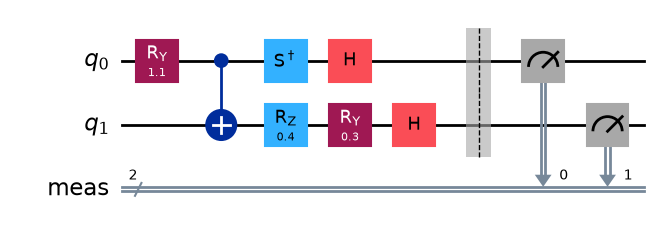

In [16]:
rotate_for_pauli(state, "XY").draw("mpl", fold=-1)

### Practice 6.5 — Measure a Pauli string by hand

Write `ex5_measure(circuit, label)` that returns a new circuit: a copy of `circuit`, followed by the
basis change for every qubit whose Pauli in `label` is `X` or `Y`, followed by `measure_all()`. Use
little-endian indexing (`label[-1]` is qubit 0). The check runs your circuits with
`SamplerV2(mode=AerSimulator())`, computes $\langle P\rangle$ with `parity_expval`, and compares with the
exact value from `Statevector`.

In [ ]:
def ex5_measure(circuit, label):
    qc = circuit.copy()
    # TODO: add the basis change for X and Y on the right qubits
    qc.measure_all()
    return qc

In [ ]:
# Run this cell to check your answer
ex5_state = QuantumCircuit(3)
ex5_state.ry(0.8, 0); ex5_state.cx(0, 1); ex5_state.rx(0.5, 2); ex5_state.cx(1, 2); ex5_state.s(0)
ex5_sampler = SamplerV2(mode=AerSimulator())
ex5_sampler.options.simulator.seed_simulator = 7
for ex5_label in ["XIZ", "IYX", "YZY", "ZXI"]:
    ex5_counts = ex5_sampler.run([ex5_measure(ex5_state, ex5_label)], shots=40_000).result()[0].data.meas.get_counts()
    ex5_mine = parity_expval(ex5_counts, ex5_label)
    ex5_ref = Statevector(ex5_state).expectation_value(SparsePauliOp(ex5_label)).real
    assert abs(ex5_mine - ex5_ref) < 0.02, f"<{ex5_label}>: {ex5_mine:+.3f} vs exact {ex5_ref:+.3f}"
assert ex5_state.num_clbits == 0, "do not modify the input circuit"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex5_measure(circuit, label):
    qc = circuit.copy()
    for q, p in enumerate(reversed(label)):
        if p == "X":
            qc.h(q)
        elif p == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc
```

$H$ maps the $X$ eigenbasis to the $Z$ eigenbasis and $HS^\dagger$ (first $S^\dagger$, then $H$) does
the same for $Y$. Applying only $H$ for a $Y$ would measure $\langle X\rangle$ instead, and using $S$
instead of $S^\dagger$ measures $-\langle Y\rangle$. The other common slip is the qubit order: position
`i` of the label string acts on qubit `n-1-i`.

</details>

### 6.2.2 Grouping commuting terms

Terms that are qubit-wise commuting (QWC: on every qubit the two Paulis are equal or one of them is
$I$) can be read from the same measured circuit, because one set of single-qubit basis rotations
diagonalizes all of them. Each QWC group is one measurement setting (one circuit per parameter set).
Terms that commute only as whole strings, like $XX$, $YY$, $ZZ$, share an eigenbasis too, but measuring
them together needs an entangling basis change (Bell basis), so backend estimators use QWC grouping.
The 0.40 `default_shots` docstring describes exactly this: a "physical measurement basis" groups
qubit-wise commuting observables of one circuit and parameter set into a single measurement. The local
Runtime Estimator also groups QWC terms within each PUB.

In [17]:
H_ising = SparsePauliOp(["ZZI", "IZZ", "ZIZ", "XII", "IXI", "IIX"])
H_heis = SparsePauliOp(["XX", "YY", "ZZ"])

for name, op in [("transverse-field Ising", H_ising), ("2-qubit Heisenberg", H_heis)]:
    qwc = op.paulis.group_commuting(qubit_wise=True)
    full = op.paulis.group_commuting(qubit_wise=False)
    print(f"{name}: {len(op)} terms -> {len(qwc)} QWC settings {[g.to_labels() for g in qwc]}, "
          f"{len(full)} general-commuting group(s)")

transverse-field Ising: 6 terms -> 2 QWC settings [['ZZI', 'IZZ', 'ZIZ'], ['XII', 'IXI', 'IIX']], 2 general-commuting group(s)
2-qubit Heisenberg: 3 terms -> 3 QWC settings [['XX'], ['YY'], ['ZZ']], 1 general-commuting group(s)


Q6.6. How many measurement settings does an Estimator that groups qubit-wise commuting terms need for

```python
H = SparsePauliOp(["XXI", "IXX", "XIX", "ZZI", "IZZ", "ZIZ"])
```

A. 1

B. 2

C. 3

D. 6

<details>
<summary>Show answer</summary>

Answer: B

All $X$-type strings are qubit-wise commuting with each other (one setting: $H$ on every qubit), and so
are all $Z$-type strings (no rotation). `H.paulis.group_commuting(qubit_wise=True)` returns 2 groups.
Mixed pairs such as `XXI` and `ZIZ` anticommute, so 1 setting is impossible; 6 would be measuring each
term separately.

</details>

### 6.2.3 Variance, standard error and precision

A single shot of a Pauli observable returns $\pm1$, so its variance is

$$\operatorname{Var}(P)=\langle P^2\rangle-\langle P\rangle^2 = 1-\langle P\rangle^2 \le 1,
\qquad \sigma_{\langle P\rangle}=\sqrt{\frac{1-\langle P\rangle^2}{N}}\le\frac{1}{\sqrt N}.$$

Setting the worst case equal to the requested precision $\varepsilon$ gives $N=1/\varepsilon^2$, the
conversion used in 6.1.4. For $O=\sum_k a_k P_k$, the local Runtime Estimator reports the bound
$\sigma \approx \sum_k |a_k|\sqrt{\operatorname{Var}(P_k)}/\sqrt N$. The plot repeats a $\langle Z\rangle$
estimate 300 times for each shot count and compares the spread with these formulas.

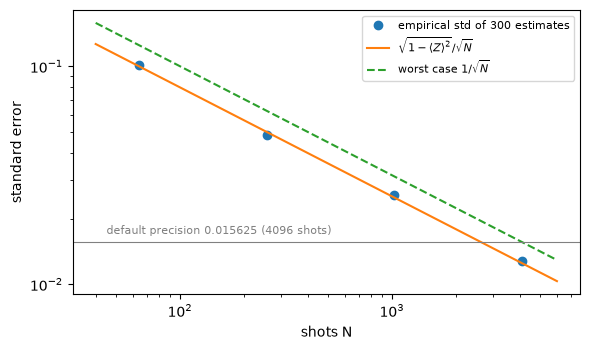

N=   64: empirical 0.1013, formula 0.1000
N=  256: empirical 0.0484, formula 0.0500
N= 1024: empirical 0.0256, formula 0.0250
N= 4096: empirical 0.0128, formula 0.0125


In [18]:
z_target = 0.6
prep = QuantumCircuit(1)
prep.ry(2 * np.arccos(np.sqrt((1 + z_target) / 2)), 0)      # <Z> = 0.6
prep.measure_all()

repeats, shot_list = 300, [64, 256, 1024, 4096]
spread = []
sampler = SamplerV2(mode=AerSimulator())
sampler.options.simulator.seed_simulator = 2026
for n in shot_list:
    bits = sampler.run([prep], shots=repeats * n).result()[0].data.meas.array[:, 0]  # 0/1 per shot
    z = (1 - 2 * bits.astype(float)).reshape(repeats, n).mean(axis=1)            # 300 estimates
    spread.append(z.std(ddof=1))

n_grid = np.logspace(np.log10(40), np.log10(6000), 50)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(shot_list, spread, "o", label="empirical std of 300 estimates")
ax.loglog(n_grid, np.sqrt(1 - z_target**2) / np.sqrt(n_grid), label=r"$\sqrt{1-\langle Z\rangle^2}/\sqrt{N}$")
ax.loglog(n_grid, 1 / np.sqrt(n_grid), "--", label=r"worst case $1/\sqrt{N}$")
ax.axhline(0.015625, color="gray", lw=0.8)
ax.annotate("default precision 0.015625 (4096 shots)", (45, 0.017), fontsize=8, color="gray")
ax.set_xlabel("shots N"); ax.set_ylabel("standard error"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for n, s in zip(shot_list, spread):
    print(f"N={n:5d}: empirical {s:.4f}, formula {np.sqrt(1 - z_target**2) / np.sqrt(n):.4f}")

In [19]:
# The stds reported by the local Runtime Estimator follow the same formula
chk = EstimatorV2(mode=manila_sim, options={"simulator": {"seed_simulator": 9}}).run([(isa_bell, isa_zz)]).result()[0]
ev, shots = float(chk.data.evs), chk.metadata["shots"]
print(f"reported std {float(chk.data.stds):.6f}  vs  sqrt(1-ev^2)/sqrt(shots) = {np.sqrt(1 - ev**2) / np.sqrt(shots):.6f}")

reported std 0.007633  vs  sqrt(1-ev^2)/sqrt(shots) = 0.007633


Precision scales as $1/\sqrt{N}$: ten times better precision costs a hundred times more shots.
`precision` is a target; the reported `stds` are the estimated standard errors, which can be smaller
(if $|\langle P\rangle|$ is close to 1) or larger (mitigation such as TREX, ZNE or PEC inflates the
variance).

Q6.7. A Pauli observable has $\langle P\rangle\approx 0.6$. Roughly how many shots are needed for a standard
error of 0.01?

A. 1,600

B. 3,600

C. 10,000

D. 6,400

<details>
<summary>Show answer</summary>

Answer: D

$N = (1-\langle P\rangle^2)/\sigma^2 = (1-0.36)/0.0001 = 6400$. 10,000 is the worst-case estimate
$1/\sigma^2$ (for $\langle P\rangle = 0$), which is what the precision-to-shots conversion assumes when it
does not know the value in advance.

</details>

### 6.2.4 Error suppression, mitigation and correction

> **Study priority.** Keep the purpose of DD, twirling, TREX, ZNE, PEA and PEC on the core path. Implementing a noise amplifier or extrapolator from scratch is a separate extension.

- Error suppression changes how the circuit is executed so that fewer errors happen or so that noise
  takes a simpler form: dynamical decoupling and Pauli twirling (in a broad sense also noise-aware
  transpilation). Applied during compilation and execution; no post-processing of the result.
- Error mitigation runs an ensemble of related (noisy) circuits and post-processes the outcomes to
  reduce the bias of an expectation value: TREX, ZNE (with gate folding or PEA), PEC. It costs extra
  circuits or shots and is an Estimator feature.
- Error correction (QEC) encodes logical qubits in many physical qubits and detects/corrects errors
  during the computation. It is not an Estimator option.

| Technique | Type | Option | What it does | Cost | Bias |
|---|---|---|---|---|---|
| Dynamical decoupling | suppression | `dynamical_decoupling.enable` | inserts pulse sequences (`XX`, `XpXm`, `XY4`) that multiply to identity on idle qubits | none in shots; can hurt densely packed circuits | reduces coherent idle errors |
| Pauli twirling | suppression (noise tailoring) | `twirling.enable_gates`, `twirling.enable_measure` | random Paulis around 2-qubit gates / measurements with the same ideal action → noise becomes a Pauli (stochastic) channel | shots split over randomizations | coherent errors no longer add up quadratically |
| TREX | mitigation | `resilience.measure_mitigation` | measurement twirling (X, measure, flip bit) diagonalizes the readout-error matrix; a rescaling factor is learned from $\lvert 0\rangle$ circuits | small (calibration circuits) | removes readout bias |
| ZNE | mitigation | `resilience.zne_mitigation` | runs at amplified noise $\lambda$ (e.g. 1, 3, 5), fits and extrapolates to $\lambda=0$ | ≈ number of noise factors | reduced, not guaranteed unbiased (model-dependent) |
| PEA | mitigation (ZNE amplifier) | `resilience.zne.amplifier="pea"` | learns each entangling layer's twirled noise, amplifies by injecting noise proportional to it | noise learning + ZNE | more accurate amplification than folding; used for utility-scale runs |
| PEC | mitigation | `resilience.pec_mitigation` | writes the ideal circuit as a quasi-probability mix of noisy ones: $\mathcal O_\text{ideal}=\sum_i\eta_i\mathcal O_{\text{noisy},i}$ | shots × $\gamma^2$, $\gamma=\sum_i\lvert\eta_i\rvert$ grows exponentially with depth; capped by `pec.max_overhead` (100) | unbiased (for the learned noise model) |

A few precise points the exam likes:
- Gate folding replaces a gate $U$ by $U(U^\dagger U)^k$, which is the identity ideally and amplifies its
  noise by $\lambda = 2k+1$ (so 1, 3, 5, …). `gate_folding_front` / `gate_folding_back` decide which gates
  are folded when a fractional factor needs only some of them.
- PEA requires ZNE to be on and always uses gate twirling; PEA and PEC both rely on learned layer noise
  (`layer_noise_learning`, or a model passed in `resilience.layer_noise_model`).
- DD only helps where qubits sit idle. In a circuit where every qubit is busy all the time it has nothing
  to fill and may even add errors.
- Pauli twirling on its own reduces coherent error build-up (coherent errors grow roughly quadratically
  with the number of gates, Pauli errors linearly); it is also what makes TREX, PEA and PEC work.

Q6.8. Which technique is an error suppression technique rather than an error mitigation technique?

A. Dynamical decoupling

B. Twirled readout error extinction (TREX)

C. Zero-noise extrapolation (ZNE)

D. Probabilistic error cancellation (PEC)

<details>
<summary>Show answer</summary>

Answer: A

DD inserts identity-equivalent pulse sequences on idle qubits while the circuit runs, which prevents
errors (suppression). TREX, ZNE and PEC run extra circuits and post-process the results to reduce the bias
of expectation values (mitigation). Note that none of the four is error correction.

</details>

### 6.2.5 Bypass runtime mitigation and implement ZNE yourself

> **Optional extension.** Implement ZNE, partial folding and Richardson extrapolation. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s6-resume-74). Later core code does not require this block.

On hardware you would set `resilience_level=0` (optionally keeping `dynamical_decoupling`) so that the
service does not mitigate, then build the noise-amplified circuits and do the fit yourself. We do exactly
that on `AerSimulator.from_backend(FakeManilaV2())`, whose local runs are unmitigated anyway.

1. Transpile once to an ISA circuit.
2. Fold every two-qubit gate $G \to G\,(G^\dagger G)^k$ for $\lambda = 2k+1 \in\{1,3,5\}$. Folding is done
   on the ISA circuit and the folded circuits are not transpiled again (the transpiler would cancel
   the inserted pairs).
3. Estimate $\langle O\rangle(\lambda)$ for each $\lambda$ and extrapolate to $\lambda = 0$.

The test circuit prepares a 3-qubit GHZ state, then un-prepares and re-prepares it twice (barriers
keep the transpiler from cancelling those pairs), so it has 10 CX gates and the ideal $\langle XXX\rangle$ is 1.

In [20]:
def fold_two_qubit_gates(isa_circuit, noise_factor):
    # Full folding: every 2-qubit gate G becomes G (G^dagger G)^k with noise_factor = 2k + 1.
    if noise_factor < 1 or noise_factor % 2 != 1:
        raise ValueError("full folding needs an odd integer noise factor")
    folded = isa_circuit.copy_empty_like()
    for inst in isa_circuit.data:
        folded.append(inst)
        if inst.operation.num_qubits == 2:
            for _ in range((noise_factor - 1) // 2):
                folded.append(inst.operation.inverse(), inst.qubits)
                folded.append(inst.operation, inst.qubits)
    return folded

zne_qc = QuantumCircuit(3)
zne_qc.h(0); zne_qc.cx(0, 1); zne_qc.cx(1, 2)
for _ in range(2):
    zne_qc.barrier(); zne_qc.cx(1, 2); zne_qc.cx(0, 1)
    zne_qc.barrier(); zne_qc.cx(0, 1); zne_qc.cx(1, 2)
zne_obs = SparsePauliOp("XXX")
print("ideal <XXX> =", Statevector(zne_qc).expectation_value(zne_obs).real)

pm_zne = generate_preset_pass_manager(optimization_level=1, backend=manila_sim,
                                      initial_layout=[0, 1, 2], seed_transpiler=3)
zne_isa = pm_zne.run(zne_qc)
zne_isa_obs = zne_obs.apply_layout(zne_isa.layout)

noise_factors = [1, 3, 5]
folded_circuits = [fold_two_qubit_gates(zne_isa, lam) for lam in noise_factors]
for lam, fc in zip(noise_factors, folded_circuits):
    print(f"lambda={lam}: {fc.count_ops()['cx']:2d} CX gates, same unitary as lambda=1: "
          f"{Operator(fc).equiv(Operator(zne_isa))}")

ideal <XXX> = 0.9999999999999998
lambda=1: 10 CX gates, same unitary as lambda=1: True
lambda=3: 30 CX gates, same unitary as lambda=1: True
lambda=5: 50 CX gates, same unitary as lambda=1: True


In [21]:
def extrapolate(lams, values):
    lams, values = np.asarray(lams, float), np.asarray(values, float)
    linear = np.polyval(np.polyfit(lams, values, 1), 0.0)                  # least-squares line
    richardson = np.polyval(np.polyfit(lams, values, len(lams) - 1), 0.0)  # polynomial through all points
    slope, intercept = np.polyfit(lams, np.log(values), 1)                 # values = A exp(-lam / tau)
    exponential = np.exp(intercept)
    return {"linear": linear, "Richardson": richardson, "exponential": exponential}

def run_zne(mode):
    est = EstimatorV2(mode=mode, options={"default_precision": 0.005,            # 40,000 shots per point
                                         "simulator": {"seed_simulator": 1234}})
    result = est.run([(fc, zne_isa_obs) for fc in folded_circuits]).result()
    return np.array([float(r.data.evs) for r in result])

raw_full = run_zne(manila_sim)                                              # full device noise model
no_readout = AerSimulator(noise_model=NoiseModel.from_backend(manila, readout_error=False))
raw_gate_only = run_zne(no_readout)                                         # same noise, readout errors removed

for name, raw in [("Aer model of FakeManilaV2 (full noise)", raw_full), ("same noise without readout error", raw_gate_only)]:
    fits = extrapolate(noise_factors, raw)
    print(f"{name}\n   raw <XXX>(lambda=1,3,5) = {np.round(raw, 3)}")
    print("   extrapolated to 0: " + ", ".join(f"{k} {v:.3f}" for k, v in fits.items()) + "   (ideal 1.000)")

Aer model of FakeManilaV2 (full noise)
   raw <XXX>(lambda=1,3,5) = [0.61  0.446 0.316]
   extrapolated to 0: linear 0.678, Richardson 0.704, exponential 0.723   (ideal 1.000)
same noise without readout error
   raw <XXX>(lambda=1,3,5) = [0.844 0.624 0.446]
   extrapolated to 0: linear 0.936, Richardson 0.969, exponential 0.996   (ideal 1.000)


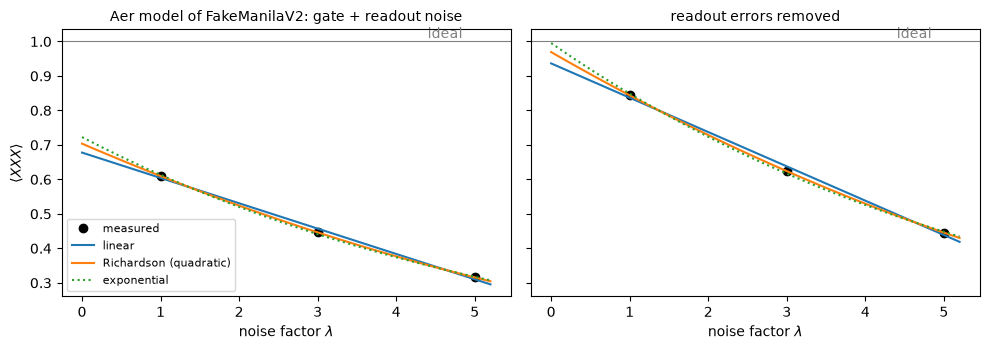

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
grid = np.linspace(0, 5.2, 100)
for ax, raw, title in [(axes[0], raw_full, "Aer model of FakeManilaV2: gate + readout noise"),
                       (axes[1], raw_gate_only, "readout errors removed")]:
    ax.plot(noise_factors, raw, "ko", label="measured")
    ax.plot(grid, np.polyval(np.polyfit(noise_factors, raw, 1), grid), label="linear")
    ax.plot(grid, np.polyval(np.polyfit(noise_factors, raw, 2), grid), label="Richardson (quadratic)")
    s, i = np.polyfit(noise_factors, np.log(raw), 1)
    ax.plot(grid, np.exp(i + s * grid), ":", label="exponential")
    ax.axhline(1.0, color="gray", lw=0.8); ax.annotate("ideal", (4.4, 1.01), color="gray")
    ax.set_title(title, fontsize=10); ax.set_xlabel(r"noise factor $\lambda$")
axes[0].set_ylabel(r"$\langle XXX\rangle$"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

What the numbers show:

- Folding amplifies gate noise, and the extrapolation removes most of it. With readout errors
  switched off, the extrapolated values land close to 1 although the raw $\lambda=1$ value is clearly below it.
- With the full noise model, all three points are scaled down by the readout error, which is the same at
  every $\lambda$ and therefore survives extrapolation. This is why the Runtime's level 2 is TREX + ZNE:
  TREX removes the readout bias, ZNE the gate-noise bias.
- The extrapolated value depends on the model (linear, polynomial, exponential) and has larger error bars
  than the raw points. ZNE reduces bias but is not guaranteed to remove it. PEC is the unbiased
  alternative, paid for with exponential sampling overhead.
- The Runtime ZNE returns `evs_noise_factors` and `stds_noise_factors`, so you can also let the service
  amplify the noise and apply your own fit.

### Practice 6.6 — Partial folding from the back

> **Optional extension.** Part of the optional block above; skip its starter and check cells together.

Fractional noise factors are reached by folding only some gates. Write `ex6_fold_back(isa_circuit, k)`
that folds only the last `k` two-qubit gates of the circuit ($G \to G\,G^\dagger G$) and leaves all
other instructions unchanged, similar to the `"gate_folding_back"` amplifier. For a circuit with $n$
two-qubit gates, the effective noise factor is $\lambda = 1 + 2k/n$.

In [ ]:
def ex6_fold_back(isa_circuit, k):
    folded = isa_circuit.copy_empty_like()
    # TODO: find the indices of the last k two-qubit gates, then append every instruction
    #       and add G^dagger G after the selected ones
    return folded

In [ ]:
# Run this cell to check your answer
ex6_n = zne_isa.count_ops()["cx"]
for ex6_k in [0, 3, ex6_n]:
    ex6_c = ex6_fold_back(zne_isa, ex6_k)
    assert ex6_c.count_ops().get("cx", 0) == ex6_n + 2 * ex6_k, f"k={ex6_k}: wrong number of CX gates"
    assert Operator(ex6_c).equiv(Operator(zne_isa)), f"k={ex6_k}: folding must not change the unitary"
def ex6_signature(c):
    return [(i.operation.name, tuple(c.find_bit(q).index for q in i.qubits)) for i in c.data]
ex6_last3 = [j for j, i in enumerate(zne_isa.data) if i.operation.num_qubits == 2][-3:]
ex6_expected = []
for j, s in enumerate(ex6_signature(zne_isa)):
    ex6_expected += [s, s, s] if j in ex6_last3 else [s]
assert ex6_signature(ex6_fold_back(zne_isa, 3)) == ex6_expected, \
    "only the LAST 3 two-qubit gates may be folded; everything else must stay in place"
print(f"n = {ex6_n} CX gates; k = 3 gives lambda = {1 + 2 * 3 / ex6_n:.1f}")
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex6_fold_back(isa_circuit, k):
    two_q = [i for i, inst in enumerate(isa_circuit.data) if inst.operation.num_qubits == 2]
    selected = set(two_q[len(two_q) - k:]) if k > 0 else set()
    folded = isa_circuit.copy_empty_like()
    for i, inst in enumerate(isa_circuit.data):
        folded.append(inst)
        if i in selected:
            folded.append(inst.operation.inverse(), inst.qubits)
            folded.append(inst.operation, inst.qubits)
    return folded
```

Each folded gate adds two copies, so the count becomes $n+2k$ and the (gate) noise factor $1+2k/n$.
Choosing the last gates corresponds to `gate_folding_back`, the first gates to `gate_folding_front`, and a
random subset to `gate_folding` (the default). Folding never changes the ideal unitary because
$G^\dagger G = I$.

</details>

### Practice 6.7 — Richardson extrapolation coefficients

> **Optional extension.** Part of the optional block above; skip its starter and check cells together.

Richardson extrapolation fits the polynomial of degree $m-1$ through $m$ points and evaluates it at 0.
This can be written as a weighted sum $E(0)=\sum_j \gamma_j E(\lambda_j)$ with

$$\gamma_j=\prod_{k\neq j}\frac{\lambda_k}{\lambda_k-\lambda_j}.$$

Implement `ex7_gammas(lams)` (returns a NumPy array of the $\gamma_j$) and
`ex7_richardson(lams, values)` (returns $E(0)$).

In [ ]:
def ex7_gammas(lams):
    lams = np.asarray(lams, dtype=float)
    return None   # TODO

def ex7_richardson(lams, values):
    return None   # TODO: use ex7_gammas

In [ ]:
# Run this cell to check your answer
ex7_g = ex7_gammas([1, 3, 5])
assert ex7_g is not None, "fill in ex7_gammas"
assert np.allclose(ex7_g, [15 / 8, -10 / 8, 3 / 8]), f"gammas for (1, 3, 5) should be (15/8, -5/4, 3/8), got {ex7_g}"
assert np.isclose(ex7_g.sum(), 1.0), "the weights must sum to 1 (a constant is reproduced exactly)"
for ex7_vals in (raw_full, raw_gate_only):
    ex7_ref = np.polyval(np.polyfit([1, 3, 5], ex7_vals, 2), 0.0)
    assert np.isclose(ex7_richardson([1, 3, 5], ex7_vals), ex7_ref), "must equal the quadratic fit at 0"
print("gammas:", ex7_g, "| sum of |gamma| =", np.abs(ex7_g).sum())
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex7_gammas(lams):
    lams = np.asarray(lams, dtype=float)
    return np.array([np.prod([lk / (lk - lj) for k, lk in enumerate(lams) if k != j])
                     for j, lj in enumerate(lams)])

def ex7_richardson(lams, values):
    return float(np.dot(ex7_gammas(lams), values))
```

For $\lambda = (1, 3, 5)$ the weights are $(15/8, -5/4, 3/8)$. They sum to 1, but they have mixed signs:
with independent errors $\sigma$ on each point, the extrapolated value has error
$\sigma\sqrt{\sum_j\gamma_j^2}\approx 2.3\,\sigma$ (and $\sum_j|\gamma_j| = 3.5$ bounds it). Extrapolation
trades bias for variance, the same trade-off that makes PEC expensive.

</details>

Q6.9. An ISA circuit contains 8 two-qubit gates. With full gate folding ($G\to G\,(G^\dagger G)^k$), how many

> **Optional extension question.** Revisit after completing the core review.
two-qubit gates does the circuit for noise factor $\lambda = 5$ contain?

A. 13

B. 24

C. 40

D. 45

<details>
<summary>Show answer</summary>

Answer: C

$\lambda = 2k+1 = 5$ means $k = 2$, so each gate becomes 5 gates: $8\times5 = 40$. The folded circuit
has the same ideal unitary; only its noise is amplified. 24 corresponds to $\lambda = 3$.

</details>

<a id="s6-core-88"></a>
<a id="s6-resume-74"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Unless stated otherwise: `from qiskit_ibm_runtime import EstimatorV2, EstimatorOptions`,
`from qiskit_aer import AerSimulator`, and `options = EstimatorOptions()` is a fresh object in every
snippet.

Q6.10. Up to shot noise, which values does this code print (in the order ZZ, XX, YY, IZ)?

```python
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.x(1)
est = EstimatorV2(mode=AerSimulator())
print(est.run([(qc, ["ZZ", "XX", "YY", "IZ"])]).result()[0].data.evs)
```

A. `1, 1, -1, ≈0`

B. `-1, -1, 1, ≈0`

C. `-1, 1, -1, ≈0`

D. `-1, 1, 1, ≈0`

<details>
<summary>Show answer</summary>

Answer: D

The circuit prepares $(|01\rangle+|10\rangle)/\sqrt2$. The two qubits are anti-correlated in $Z$
($\langle ZZ\rangle=-1$), while $\langle XX\rangle=\langle YY\rangle=+1$ for this state, and each single
qubit is maximally mixed ($\langle IZ\rangle = 0$). The first three values are exactly $\pm1$ even with
shots, because the state is an eigenstate of $ZZ$, $XX$ and $YY$; only $\langle IZ\rangle$ shows shot
noise (about $\pm0.016$ at the default 4096 shots). A is the result for the Bell state
$(|00\rangle+|11\rangle)/\sqrt2$.

</details>

Q6.11. Up to shot noise, which values does this code print (in the order IZ, ZI, XI)?

```python
qc = QuantumCircuit(2)
qc.x(0)
qc.h(1)
est = EstimatorV2(mode=AerSimulator())
print(est.run([(qc, ["IZ", "ZI", "XI"])]).result()[0].data.evs)
```

A. `1, ≈0, 1`

B. `-1, ≈0, 1`

C. `-1, 1, ≈0`

D. `≈0, -1, ≈0`

<details>
<summary>Show answer</summary>

Answer: B

Labels are little-endian: `"IZ"` is $Z$ on qubit 0, which is in $|1\rangle$, so $-1$. `"ZI"` is $Z$ on
qubit 1, which is in $|+\rangle$, so about 0 (shot noise); `"XI"` is $X$ on qubit 1, so $+1$.
D comes from reading the labels left to right (first character = qubit 0): then `"IZ"` is $Z$ on the
$|+\rangle$ qubit (0), `"ZI"` is $Z$ on the $|1\rangle$ qubit ($-1$) and `"XI"` is $X$ on the $|1\rangle$
qubit (0). C is the result without the `h(1)` (qubit 1 left in $|0\rangle$). A assigns $\langle Z\rangle=+1$
to $|1\rangle$, i.e. gets the sign of the $Z$ eigenvalue wrong.

</details>

Q6.12. A Runtime Estimator PUB was run with `precision=0.02`. You need the standard error to go down to 0.005.
By roughly what factor does the number of shots grow?

A. ×2

B. ×4

C. ×16

D. ×8

<details>
<summary>Show answer</summary>

Answer: C

shots ≈ 1/precision²: $1/0.02^2 = 2{,}500$ and $1/0.005^2 = 40{,}000$, a factor of 16. The precision
improved by a factor of 4, and shots scale with its square. B would be right for halving the precision
value (0.02 → 0.01).

</details>

Q6.13. What is printed?

```python
a, b = Parameter("a"), Parameter("b")
qc = QuantumCircuit(2)
qc.ry(a, 0)
qc.ry(b, 1)
obs = [["ZI"], ["IZ"], ["ZZ"]]
vals = np.random.rand(4, 2)
res = EstimatorV2(mode=AerSimulator()).run([(qc, obs, vals)]).result()
print(res[0].data.evs.shape)
```

A. `(3, 4)`

B. `(4, 3)`

C. `(3, 4, 2)`

D. A `ValueError` because the shapes are not broadcastable.

<details>
<summary>Show answer</summary>

Answer: A

The observables have shape `(3, 1)`. The parameter values `(4, 2)` describe 4 bindings of 2 parameters;
the last axis is the parameter axis and is not part of the PUB shape, so the bindings have shape `(4,)`.
`(3, 1)` broadcast with `(4,)` gives `(3, 4)`. A flat observable list of shape `(3,)` would raise the
`ValueError` in D.

</details>

Q6.14. Which statement about `default_shots` and `default_precision` in `EstimatorOptions` is correct?

A. `default_precision` always overrides `default_shots`.

B. Setting both raises a `ValidationError`.

C. `default_shots` is ignored by the Estimator; only the Sampler uses shots.

D. If both are set, `default_shots` is used; a precision given in a PUB or in `run()` still takes precedence over both.

<details>
<summary>Show answer</summary>

Answer: D

The `default_shots` docstring says that, if set, it overrides `default_precision`. Both are only
defaults: PUB precision and the `run(..., precision=)` argument come first (and explicitly set twirling
randomizations × shots per randomization also rank above them). Setting both is allowed.

</details>

Q6.15. Which two statements about Runtime `EstimatorV2` resilience levels are true? (Select two.)

A. `resilience_level=2` enables probabilistic error cancellation.

B. The default level, 1, applies TREX with measurement twirling.

C. `resilience_level=3` selects PEC.

D. `resilience_level=2` guarantees an unbiased estimate.

E. With `resilience_level=0` you can still enable ZNE through `options.resilience.zne_mitigation = True`.

F. Level 1 adds gate twirling to reduce two-qubit gate errors.

<details>
<summary>Show answer</summary>

Answer: B, E

Level 1 (default) = TREX with measurement twirling; explicit options are applied on top of the level, so
ZNE can be switched on at level 0. Level 2 = level 1 + ZNE + gate twirling, which reduces bias but is not
guaranteed unbiased (D). No level enables PEC (A), and `resilience_level=3` raises a `ValidationError`
because the maximum is 2 (C). Gate twirling belongs to level 2, not 1 (F).

</details>

Q6.16. Which snippet enables zero-noise extrapolation with a quadratic extrapolation without raising an error?

> **Deeper API practice — optional on the first pass.** Choosing a particular polynomial extrapolator and satisfying its minimum-point validation is second-pass ZNE option practice.

A.

```python
options.zne_mitigation = True
options.zne.extrapolator = "polynomial_degree_2"
```

B.

```python
options.resilience.zne_mitigation = True
options.resilience.zne.extrapolator = "richardson"
```

C.

```python
options.resilience.zne_mitigation = True
options.resilience.zne.noise_factors = [1, 3, 5]
options.resilience.zne.extrapolator = "polynomial_degree_2"
```

D.

```python
options.resilience.zne_mitigation = True
options.resilience.zne.noise_factors = [0, 1, 3]
options.resilience.zne.extrapolator = "polynomial_degree_2"
```

<details>
<summary>Show answer</summary>

Answer: C

ZNE lives under `options.resilience`; `polynomial_degree_2` needs at least 3 noise factors, all ≥ 1.
A uses a non-existent top-level path (`ValidationError: Object has no attribute 'zne_mitigation'`).
B: `"richardson"` is not an allowed extrapolator name. D: noise factors must be ≥ 1 (the unamplified
circuit is $\lambda=1$; $\lambda=0$ is where you extrapolate to, not something you can run).

</details>

Q6.17. Which configuration uses probabilistic error amplification (PEA)?

A.

```python
options.resilience.pec_mitigation = True
options.resilience.pec.amplifier = "pea"
```

B.

```python
options.resilience.zne_mitigation = True
options.resilience.zne.amplifier = "pea"
```

C.

```python
options.twirling.enable_gates = True
options.twirling.strategy = "pea"
```

D.

```python
options.resilience.layer_noise_learning.amplifier = "pea"
```

<details>
<summary>Show answer</summary>

Answer: B

PEA is a noise amplifier for ZNE, so ZNE must be enabled and `zne.amplifier` set to `"pea"`. `PecOptions`
has no `amplifier` field (A), `"pea"` is not a twirling strategy (C), and `LayerNoiseLearningOptions`
configures the learning step but has no `amplifier` (D). All three raise a `ValidationError`.

</details>

Q6.18. This job runs on a real backend. Which techniques does it use? (Select three.)

```python
estimator = EstimatorV2(mode=backend)
estimator.options.resilience.zne_mitigation = True
estimator.options.resilience.zne.amplifier = "pea"
job = estimator.run([(isa_circuit, isa_observable)])
```

A. Zero-noise extrapolation (ZNE)

B. Probabilistic error cancellation (PEC)

C. Twirled readout error extinction (TREX)

D. Probabilistic error amplification (PEA)

E. Dynamical decoupling

<details>
<summary>Show answer</summary>

Answer: A, C, D

`resilience_level` was not set, so the default level 1 applies and TREX (with measurement twirling)
stays on. The explicit options add ZNE with PEA as the noise amplifier on top (and PEA forces gate
twirling). PEC and DD are off by default. Answering only "ZNE and PEA" forgets the level-1 baseline; to
get ZNE/PEA alone you would also set `resilience_level=0` or `resilience.measure_mitigation=False`.

</details>

Q6.19. Which statement about probabilistic error cancellation (PEC) in the Runtime Estimator is correct?

> **Deeper API practice — optional on the first pass.** PEC concepts remain in the theory overview; the exact overhead formula and default cap are deeper details.

A. It gives an unbiased estimate, but its sampling overhead scales with $\gamma^2$, where $\gamma$ grows exponentially with circuit depth; `resilience.pec.max_overhead` (default 100) caps it.

B. It is switched on by `resilience_level=2`.

C. It amplifies the noise by gate folding and extrapolates to zero noise.

D. It can be combined with ZNE by setting both `pec_mitigation` and `zne_mitigation` to `True`.

<details>
<summary>Show answer</summary>

Answer: A

PEC represents the ideal circuit as a quasi-probability combination of noisy circuits; the negativity
$\gamma=\sum|\eta_i|$ sets the shot overhead ($\propto\gamma^2$), which grows exponentially with depth.
No resilience level enables it (B), C describes ZNE, and PEC + ZNE is rejected by option validation (D).

</details>

Q6.20. Which two assignments raise an exception? Each line is applied to a fresh `EstimatorOptions()` (Select two.)

> **Deeper API practice — optional on the first pass.** Exact validation combinations are deeper options API practice.

A. `options.dynamical_decoupling.sequence_type = "XY4"`

B. `options.resilience.zne.noise_factors = [1, 1.5, 2]`

C. `options.resilience_level = 3`

D. `options.resilience.zne.extrapolator = "polynomial_degree_3"`

E. `options.twirling.strategy = "all"`

<details>
<summary>Show answer</summary>

Answer: C, D

C: the maximum `resilience_level` of `EstimatorV2` is 2. D: a cubic fit needs at least 4 noise factors,
but the default is `(1, 3, 5)`, so the model validator raises
`polynomial_degree_3 requires at least 4 noise_factors`. `XY4`, fractional noise factors ≥ 1 and the
`"all"` twirling strategy are all valid.

</details>

Q6.21. With qiskit-ibm-runtime 0.40 you run the following in local testing mode. What happens?

> **Deeper API practice — optional on the first pass.** The exact warning and fallback in runtime 0.40 are additional local-mode debugging practice.

```python
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
estimator = EstimatorV2(mode=AerSimulator.from_backend(FakeManilaV2()), options={"resilience_level": 2})
job = estimator.run([(isa_circuit, isa_observable)])
print(job.result()[0].data.evs)
```

A. `run()` raises a `ValueError` because Aer simulators do not accept resilience options.

B. TREX and ZNE are simulated locally, so the printed value is mitigated.

C. The job is sent to the real `ibm_manila` device through the saved account.

D. A `UserWarning` says the option has no effect in local testing mode, and an unmitigated noisy simulation is returned.

<details>
<summary>Show answer</summary>

Answer: D

Local testing mode runs a noisy Aer simulation of the device model. It honours only the
precision/shots settings and `simulator.seed_simulator`; for `resilience_level` it warns
`The resilience_level option has no effect in local testing mode.` Aer never contacts IBM Quantum.

</details>

Q6.22. You pass a circuit that ends with `measure_all()` to an Estimator. Which statement is correct?

A. Terminal measurements are ignored, so the correct expectation values are returned.

B. Estimator circuits must not contain measurements: the Runtime Estimator does not raise, but it measures after your measurements and can silently return wrong values, so remove them first.

C. The measurement outcomes are returned in `result[0].data.meas` next to `evs`.

D. The measurements are needed to tell the Estimator which qubits the observable acts on.

<details>
<summary>Show answer</summary>

Answer: B

The Estimator adds its own basis rotations and measurements. The local Runtime Estimator does not
raise; it measures after your measurements, so for example $\langle XX\rangle$ of a Bell state comes back
near 0 instead of 1 (A is therefore wrong). Use `remove_final_measurements()`. The observable, not measurements, defines the qubits (D); `data.meas` is
a Sampler field (C).

</details>

Q6.23. `result = estimator.run([pub0, pub1]).result()`. Which expression returns the standard errors of the
second PUB?

A. `result.data[1].stds`

B. `result[1].stds`

C. `result[1].data.stds`

D. `result[1].data.evs.std()`

<details>
<summary>Show answer</summary>

Answer: C

`PrimitiveResult` is indexed per PUB; each `PubResult` keeps its arrays in `.data` (`evs`, `stds`, …).
A and B raise `AttributeError`. D computes the spread of the expectation values across the PUB's
broadcast shape, which is not a standard error.

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Estimator essentials

| Item | Remember |
|---|---|
| PUB | `(circuit, observables[, parameter_values[, precision]])`; no measurements in the circuit |
| Run | `estimator.run([pub, ...], precision=None)` (precision is keyword-only) → `job.result()[i].data.evs / .stds`, `.metadata` |
| Observables | `"XZ"`, `Pauli`, `SparsePauliOp(labels, coeffs)`, `.from_list`, `.from_sparse_list`, `.from_operator`; right-most label = qubit 0 |
| ISA | `pm = generate_preset_pass_manager(optimization_level=1, backend=backend)`; `isa = pm.run(qc)`; `isa_obs = obs.apply_layout(isa.layout)` |
| No transpilation in V2 | primitives never transpile; `optimization_level` / `transpilation.*` options → `ValidationError`; non-ISA circuit → `IBMInputValueError` at `run()` |
| Shapes | `evs.shape` = broadcast(observables shape, parameter-values shape without the last axis); `[[o1], [o2]]` × `(n, p)` → `(2, n)` |
| Precision ↔ shots | shots ≈ 1/precision²; 0.015625 ↔ 4096; precision ÷ 2 → shots × 4 |
| Priority | PUB precision > `run(precision=)` > twirling randomizations × shots > `default_shots` > `default_precision` |
| Standard error | Pauli: $\sqrt{(1-\langle P\rangle^2)/N}\le 1/\sqrt N$ |
| Local runs | `EstimatorV2(mode=AerSimulator())` (ideal, shot noise only); `EstimatorV2(mode=AerSimulator.from_backend(FakeXxx()))` (device model with noise); on hardware `mode=backend`, `Session` or `Batch` |
| Local testing mode | Aer (or fake-backend) mode → local simulation, no mitigation; only precision/shots and `simulator.seed_simulator` honoured; other options warn "no effect" |

Resilience levels (Runtime `EstimatorV2`)

| Level | Enables | Notes |
|---|---|---|
| 0 | nothing | use to bypass and do your own mitigation |
| 1 (default) | TREX + measurement twirling | readout-error bias removed |
| 2 | level 1 + ZNE (gate folding) + gate twirling | bias reduced, not guaranteed zero; ≈3× the circuit executions with 3 noise factors (more QPU time: amplified circuits are deeper) |
| 3 | — | `ValidationError` (max is 2) |

Option paths

| Want | Set |
|---|---|
| TREX | `resilience.measure_mitigation = True` (`measure_noise_learning.num_randomizations`) |
| ZNE | `resilience.zne_mitigation = True`; `resilience.zne.noise_factors` (default (1, 3, 5)), `.extrapolator` (default ("exponential", "linear")), `.amplifier` |
| PEA | `resilience.zne_mitigation = True` + `resilience.zne.amplifier = "pea"` (+ `layer_noise_learning`) |
| PEC | `resilience.pec_mitigation = True`; `resilience.pec.max_overhead` (100); never together with ZNE |
| Gate / measurement twirling | `twirling.enable_gates`, `twirling.enable_measure`, `num_randomizations`, `shots_per_randomization`, `strategy` ("active-accum") |
| DD | `dynamical_decoupling.enable = True`; `sequence_type` "XX" / "XpXm" / "XY4"; `scheduling_method` "alap" / "asap" |
| Shots / precision | `default_shots`, `default_precision` |

Suppression vs mitigation vs correction

| Class | Techniques | Key fact |
|---|---|---|
| Suppression | DD, Pauli twirling | acts during execution; DD needs idle time |
| Mitigation | TREX, ZNE (folding / PEA), PEC | post-processes many noisy runs to reduce expectation-value bias; ZNE biased-but-cheap, PEC unbiased-but-exponential |
| Correction | QEC codes | logical qubits; not an Estimator option |

## Sources and further reading

Study group notebooks (Qiskit Advocate KR, 2026)
- [Section_6_Use_Estimator_Primitive](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_6_Use_Estimator_Primitive): `1_Set_Estimator_Options_ko.ipynb`, `2_Understand_Estimator_Theory_KR.ipynb`
- [Review/Practice_10_Qiskit_Primitives.ipynb](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Review) (Q1–Q3 adapted)

Textbook
- QAMP 2025 Qiskit 2.x certification tutorial, Section 6: <https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial>

Official documentation
- [Runtime options overview](https://quantum.cloud.ibm.com/docs/guides/runtime-options-overview)
- [Get started with the Estimator primitive](https://quantum.cloud.ibm.com/docs/guides/get-started-with-estimator)
- [Estimator options](https://quantum.cloud.ibm.com/docs/guides/estimator-options)
- [Estimator noise management](https://quantum.cloud.ibm.com/docs/guides/estimator-noise-management)
- [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques)
- [Specify observables in the Pauli basis](https://quantum.cloud.ibm.com/docs/guides/specify-observables-pauli)
- [Primitive inputs and outputs](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)
- [Local testing mode](https://quantum.cloud.ibm.com/docs/guides/local-testing-mode)
- Video: [An Introduction to Qiskit Runtime Primitives Version 2 (Chris Wood, QGSS 2024)](https://www.youtube.com/watch?v=OuYz02clnx4)

Option names and defaults in this notebook were checked against the installed
qiskit-ibm-runtime 0.40.1 source (`EstimatorOptions`, `ResilienceOptionsV2`, `ZneOptions`, `PecOptions`,
`MeasureNoiseLearningOptions`, `LayerNoiseLearningOptions`, `TwirlingOptions`,
`DynamicalDecouplingOptions`).

First-pass workflow review also consulted the open-source [Quantum Tokyo certification practice notebooks](https://github.com/quantum-tokyo/qiskit-certification-prep): execution-mode selection (Section 4), ISA preparation and default shots (Sections 5–6), and past-job retrieval (Section 7). Their questions were used as a style/reference check, not copied here; the official guide remains the scope reference.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [EstimatorV2 (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/estimator-v2)
- [EstimatorOptions (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/options-estimator-options)
- [Primitives (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/primitives)
- [SparsePauliOp (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.quantum_info.SparsePauliOp)
- [Get started with Estimator](https://quantum.cloud.ibm.com/docs/guides/get-started-with-estimator)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
